# Estaciones que más necesitan bicis

¿Qué estaciones se quedan sin bicis y cuántas les hacen falta? El dataset no trae inventario ni capacidad
de las estaciones, así que la necesidad se **infiere de los viajes** (septiembre 2026, viajes válidos) con dos métricas:

| Métrica | Qué mide | Cómo se calcula |
|---|---|---|
| **Déficit estructural** | La estación pierde bicis día tras día y hay que reponerlas siempre | `Neto` = arribos − retiros, promedio por día; y cuántos días del mes cerró en negativo |
| **Déficit en hora pico** | Cuántas bicis debe tener al abrir para no vaciarse durante el día | Por cada día se acumula el balance hora por hora (arribos − retiros); la caída más profunda = bicis necesarias ese día |

Una estación puede necesitar muchas bicis en la mañana aunque al final del día se llene (p. ej. junto a un
transporte masivo): por eso se usan las dos.

**Contenido**
1. Carga y cálculo de flujos
2. Balance neto del mes
3. Déficit estructural
4. Déficit en hora pico
5. Perfil horario de las estaciones críticas
6. Entre semana vs. fin de semana
7. Estructural vs. pico: tipos de estación
8. Dónde están: alcaldías y colonias
9. Mapas
10. Ranking final y conclusiones

## 1. Carga y cálculo de flujos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import folium
from branca.colormap import LinearColormap
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch

from datasetting import cargar_datos, uso_por_estacion, aplicar_estilo

aplicar_estilo()

# Misma convención que el EDA: naranja = se vacía (necesita bicis), azul = se llena
NARANJA, AZUL, GRIS, NEUTRO = "#eb6834", "#2a78d6", "#8a8984", "#e6e5e0"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIVERGENTE = LinearSegmentedColormap.from_list("vacia_llena", [NARANJA, NEUTRO, AZUL])

In [2]:
viajes, estaciones = cargar_datos()
uso = uso_por_estacion(viajes, estaciones)
print(f"{len(viajes):,} viajes válidos, {len(estaciones):,} estaciones")

1,498,099 viajes válidos, 677 estaciones


### Movimientos por estación, día y hora
Cada viaje genera dos movimientos: **−1** en la estación de retiro (a la hora del retiro) y **+1** en la de arribo (a la hora del arribo).

Ecobici no opera de 1:00 a 4:59, así que el **día operativo empieza a las 5:00**: un viaje a las 0:30 cuenta para el día anterior.
`hora_op` = horas desde las 5:00 (0 = 5:00, 19 = 0:00).

In [3]:
INICIO_DIA = 5
movs = pd.concat([
    pd.DataFrame({"est": viajes["Ciclo_Estacion_Retiro"], "t": viajes["Fecha_Hora_Retiro"], "mov": -1}),
    pd.DataFrame({"est": viajes["Ciclo_Estacion_Arribo"], "t": viajes["Fecha_Hora_Arribo"], "mov": 1}),
])
movs["dia"] = (movs["t"] - pd.Timedelta(hours=INICIO_DIA)).dt.normalize()
movs["hora_op"] = (movs["t"].dt.hour - INICIO_DIA) % 24
movs = movs[movs["dia"].between("2026-09-01", "2026-09-30")]

dias = pd.date_range("2026-09-01", "2026-09-30")
n_dias = len(dias)
idx = pd.MultiIndex.from_product([estaciones.index, dias], names=["est", "dia"])

# Balance neto por hora: filas = (estación, día), columnas = hora operativa
flujo = (movs.groupby(["est", "dia", "hora_op"])["mov"].sum()
             .unstack("hora_op", fill_value=0)
             .reindex(index=idx, columns=range(24), fill_value=0))

# Balance acumulado a lo largo del día. Su mínimo es lo más que la estación llega a "deber"
acumulado = flujo.cumsum(axis=1)
necesidad_dia = (-acumulado.min(axis=1)).clip(lower=0)            # bicis necesarias al abrir ese día
hora_pico_dia = (acumulado.idxmin(axis=1) + INICIO_DIA) % 24      # hora de reloj en que toca fondo
hora_pico_dia = hora_pico_dia[necesidad_dia > 0]
balance_dia = flujo.sum(axis=1)                                   # cierre del día

es_finde = idx.get_level_values("dia").day_of_week >= 5
flujo.shape

(20310, 24)

In [4]:
nec = pd.DataFrame({
    "Estacion": estaciones["Estacion"],
    "Alcaldia": estaciones["alcaldia"],
    "Colonia": estaciones["colonia"],
    "Retiros_dia": uso["Retiros"].reindex(estaciones.index, fill_value=0) / n_dias,
    "Neto_dia": uso["Neto"].reindex(estaciones.index, fill_value=0) / n_dias,
    "Dias_deficit": (balance_dia < 0).groupby(level="est").sum(),
    "Necesidad_mediana": necesidad_dia.groupby(level="est").median(),
    "Necesidad_p90": necesidad_dia.groupby(level="est").quantile(0.9),
    "Nec_entre_semana": necesidad_dia[~es_finde].groupby(level="est").median(),
    "Nec_fin_semana": necesidad_dia[es_finde].groupby(level="est").median(),
    "Hora_pico": hora_pico_dia.groupby(level="est").agg(lambda s: s.mode().iloc[0]),
})
nec["Etiqueta"] = [f"{i} · {n[:34]}" for i, n in zip(nec.index, nec["Estacion"])]
nec.describe().round(1)

,Retiros_dia,Neto_dia,Dias_deficit,Necesidad_mediana,Necesidad_p90,Nec_entre_semana,Nec_fin_semana,Hora_pico
count,677.0,677.0,677.0,677.0,677.0,677.0,677.0,676.0
mean,73.8,-0.0,14.9,8.8,16.8,10.1,5.8,11.8
std,45.3,11.0,7.3,13.4,19.1,15.8,4.8,5.7
min,0.0,-76.3,0.0,0.0,0.0,0.0,0.0,0.0
25%,40.8,-3.6,9.0,3.0,9.0,2.5,2.5,8.0
50%,64.4,-0.2,15.0,6.0,13.1,7.0,5.0,10.0
75%,94.1,2.9,20.0,11.0,19.3,13.0,8.0,15.0
max,375.3,119.2,30.0,262.5,357.2,309.5,56.0,23.0


## 2. Balance neto del mes

Estaciones que pierden bicis en el mes: 350 de 677 (52%)
Bicis que se pierden por día en esas estaciones: 1,970
Estaciones en déficit al menos 25 de 30 días: 81


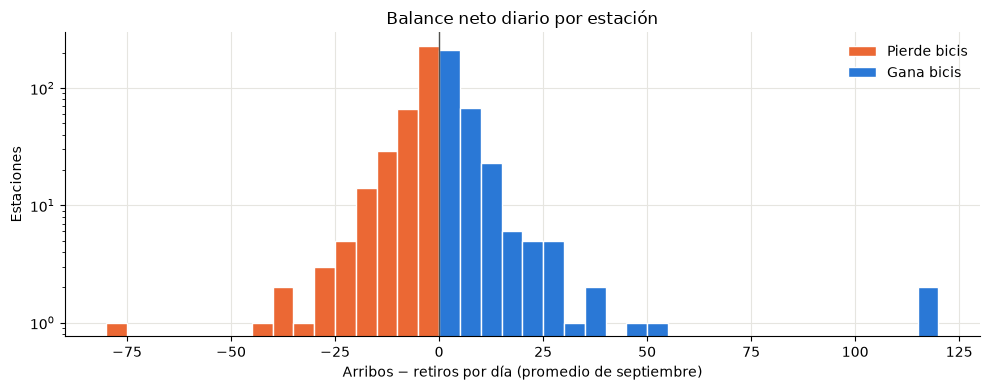

In [5]:
pierden = nec["Neto_dia"] < 0
print(f"Estaciones que pierden bicis en el mes: {pierden.sum()} de {len(nec)} ({pierden.mean():.0%})")
print(f"Bicis que se pierden por día en esas estaciones: {-nec.loc[pierden, 'Neto_dia'].sum():,.0f}")
print(f"Estaciones en déficit al menos 25 de {n_dias} días: {(nec['Dias_deficit'] >= 25).sum()}")

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(-80, 125, 5)
ax.hist(nec.loc[pierden, "Neto_dia"], bins=bins, color=NARANJA, label="Pierde bicis", edgecolor="white", linewidth=1)
ax.hist(nec.loc[~pierden, "Neto_dia"], bins=bins, color=AZUL, label="Gana bicis", edgecolor="white", linewidth=1)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set(title="Balance neto diario por estación", xlabel="Arribos − retiros por día (promedio de septiembre)",
       ylabel="Estaciones", yscale="log")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

La mayoría de las estaciones está cerca del equilibrio; el problema se concentra en una cola de estaciones
que pierden decenas de bicis por día (izquierda) y unas pocas que acumulan muchísimas (derecha). Escala log en Y para ver las colas.

## 3. Déficit estructural
Estaciones que pierden bicis **todos los días**: los usuarios salen de ahí pero no regresan. Hay que rebalancear diario
o asignarles más bicis de forma permanente. La etiqueta indica en cuántos días del mes cerró en negativo.

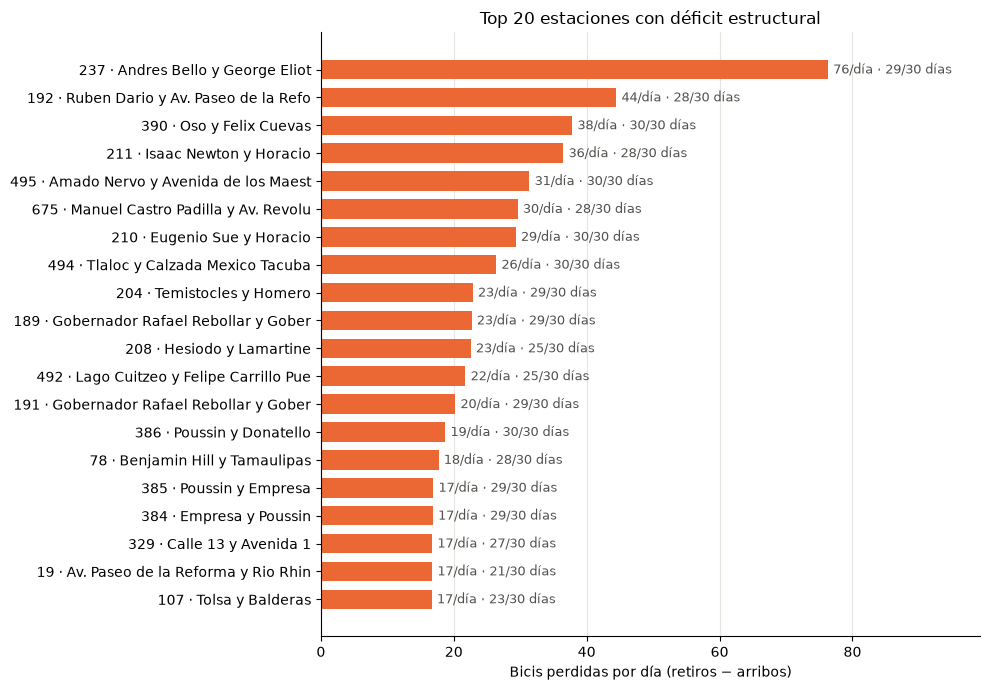

In [6]:
top_estr = nec.nsmallest(20, "Neto_dia").sort_values("Neto_dia", ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_estr["Etiqueta"], -top_estr["Neto_dia"], color=NARANJA, height=0.7)
for y, (v, d) in enumerate(zip(-top_estr["Neto_dia"], top_estr["Dias_deficit"])):
    ax.text(v + 0.8, y, f"{v:.0f}/día · {d}/{n_dias} días", va="center", fontsize=9, color="#52514e")
ax.set(title="Top 20 estaciones con déficit estructural", xlabel="Bicis perdidas por día (retiros − arribos)")
ax.set_xlim(0, -top_estr["Neto_dia"].min() * 1.3)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 4. Déficit en hora pico
**Bicis necesarias al abrir** = la caída más profunda del balance acumulado en el día. Si una estación pierde 40 bicis
entre 7:00 y 10:00 y las recupera en la tarde, igual necesita esas 40 en la mañana.
La barra es la mediana de los 30 días (un día típico); el punto es el percentil 90 (un día malo).

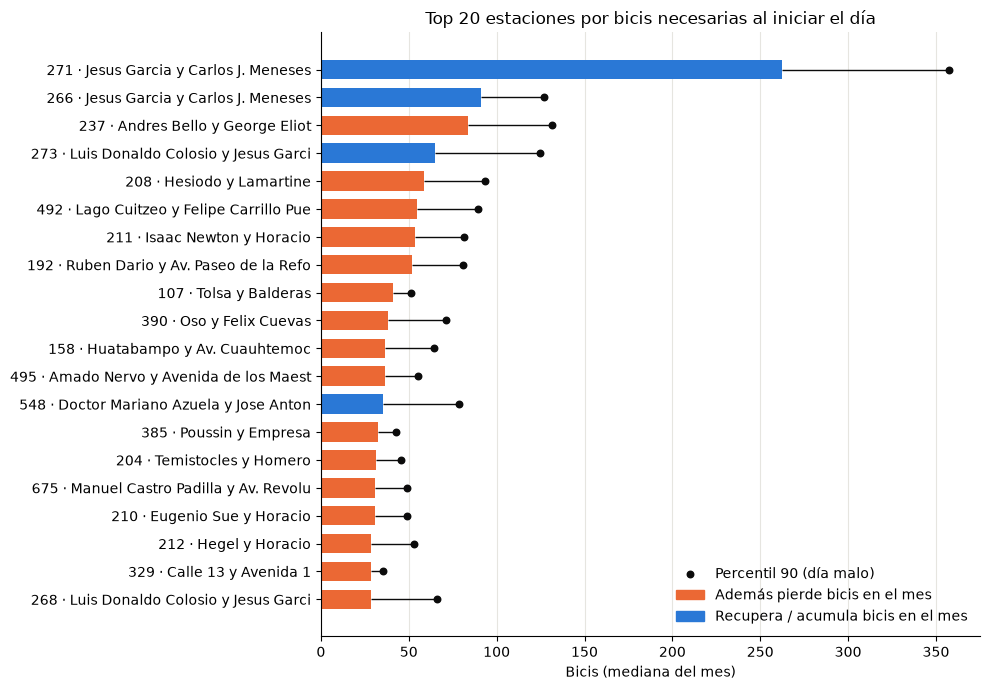

In [7]:
top_pico = nec.nlargest(20, "Necesidad_mediana").sort_values("Necesidad_mediana")

fig, ax = plt.subplots(figsize=(10, 7))
colores = np.where(top_pico["Neto_dia"] < 0, NARANJA, AZUL)
ax.barh(top_pico["Etiqueta"], top_pico["Necesidad_mediana"], color=colores, height=0.7)
ax.scatter(top_pico["Necesidad_p90"], top_pico["Etiqueta"], color="#0b0b0b", s=22, zorder=3, label="Percentil 90 (día malo)")
ax.hlines(top_pico["Etiqueta"], top_pico["Necesidad_mediana"], top_pico["Necesidad_p90"], color="#0b0b0b", linewidth=1)
ax.set(title="Top 20 estaciones por bicis necesarias al iniciar el día",
       xlabel="Bicis (mediana del mes)")
ax.grid(axis="y", visible=False)
handles, _ = ax.get_legend_handles_labels()
handles += [Patch(color=NARANJA, label="Además pierde bicis en el mes"),
            Patch(color=AZUL, label="Recupera / acumula bicis en el mes")]
ax.legend(handles=handles, frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

### ¿A qué hora se vacían?
Hora en la que el balance acumulado toca fondo (la más frecuente del mes). Antes de esa hora es cuando hay que reponer.
Solo estaciones con necesidad mediana ≥ 10 bicis.

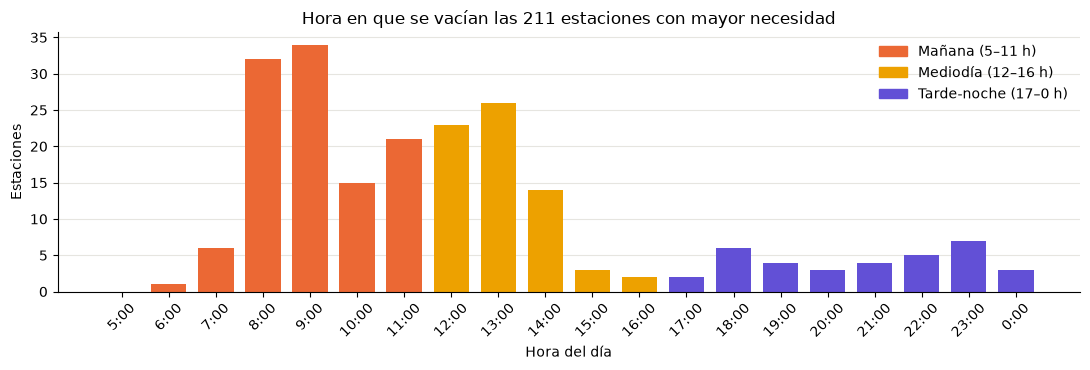

In [8]:
criticas = nec[nec["Necesidad_mediana"] >= 10]
orden_horas = [(h + INICIO_DIA) % 24 for h in range(20)]  # 5:00 … 0:00
conteo = criticas["Hora_pico"].value_counts().reindex(orden_horas, fill_value=0)

fig, ax = plt.subplots(figsize=(11, 3.8))
color_h = [NARANJA if 5 <= h <= 11 else (PAL[3] if 12 <= h <= 16 else PAL[6]) for h in conteo.index]
ax.bar([f"{h}:00" for h in conteo.index], conteo.values, color=color_h, width=0.75)
ax.set(title=f"Hora en que se vacían las {len(criticas)} estaciones con mayor necesidad",
       xlabel="Hora del día", ylabel="Estaciones")
ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(color=c, label=lab) for lab, c in
                   [("Mañana (5–11 h)", NARANJA), ("Mediodía (12–16 h)", PAL[3]), ("Tarde-noche (17–0 h)", PAL[6])]],
          frameon=False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Perfil horario de las estaciones críticas
Balance acumulado promedio a lo largo de un **día entre semana**: la curva muestra cuándo se vacía cada estación y si se recupera.

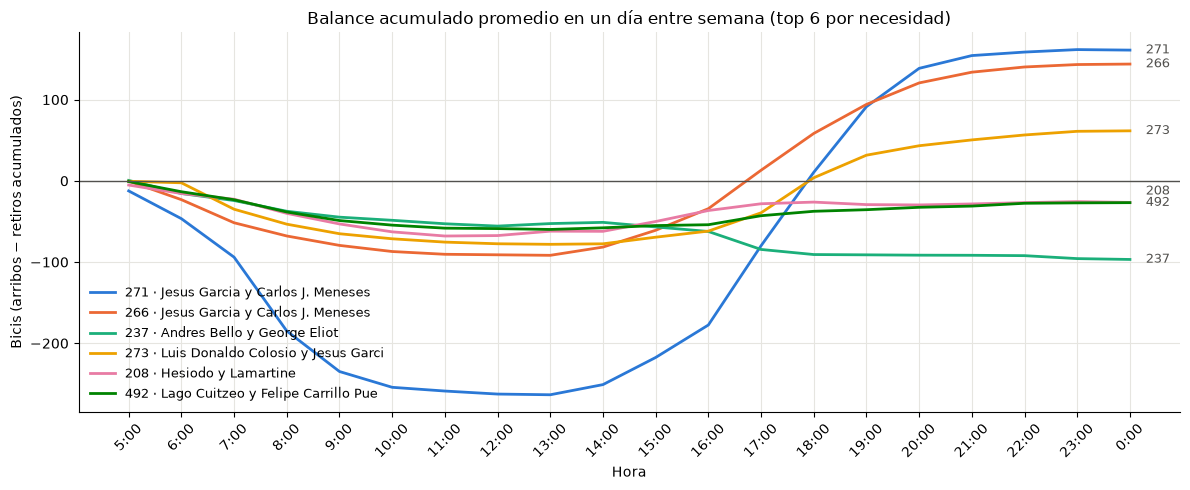

In [9]:
top6 = nec.nlargest(6, "Necesidad_mediana").index
horas_reloj = [f"{(h + INICIO_DIA) % 24}:00" for h in range(20)]

perfil = acumulado[~es_finde].groupby(level="est").mean().loc[top6, range(20)]

fig, ax = plt.subplots(figsize=(12, 5))
for color, (est, fila) in zip(PAL, perfil.iterrows()):
    ax.plot(range(20), fila.values, color=color, label=nec.loc[est, "Etiqueta"])

# Etiquetas al final de cada línea, separadas para que no se encimen
finales = perfil[19].sort_values()
pos_y = finales.values.copy()
for i in range(1, len(pos_y)):
    pos_y[i] = max(pos_y[i], pos_y[i - 1] + 14)
for est, y in zip(finales.index, pos_y):
    ax.text(19.3, y, str(est), color="#52514e", fontsize=9, va="center")
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_xticks(range(20), horas_reloj, rotation=45)
ax.set(title="Balance acumulado promedio en un día entre semana (top 6 por necesidad)",
       xlabel="Hora", ylabel="Bicis (arribos − retiros acumulados)")
ax.legend(frameon=False, fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

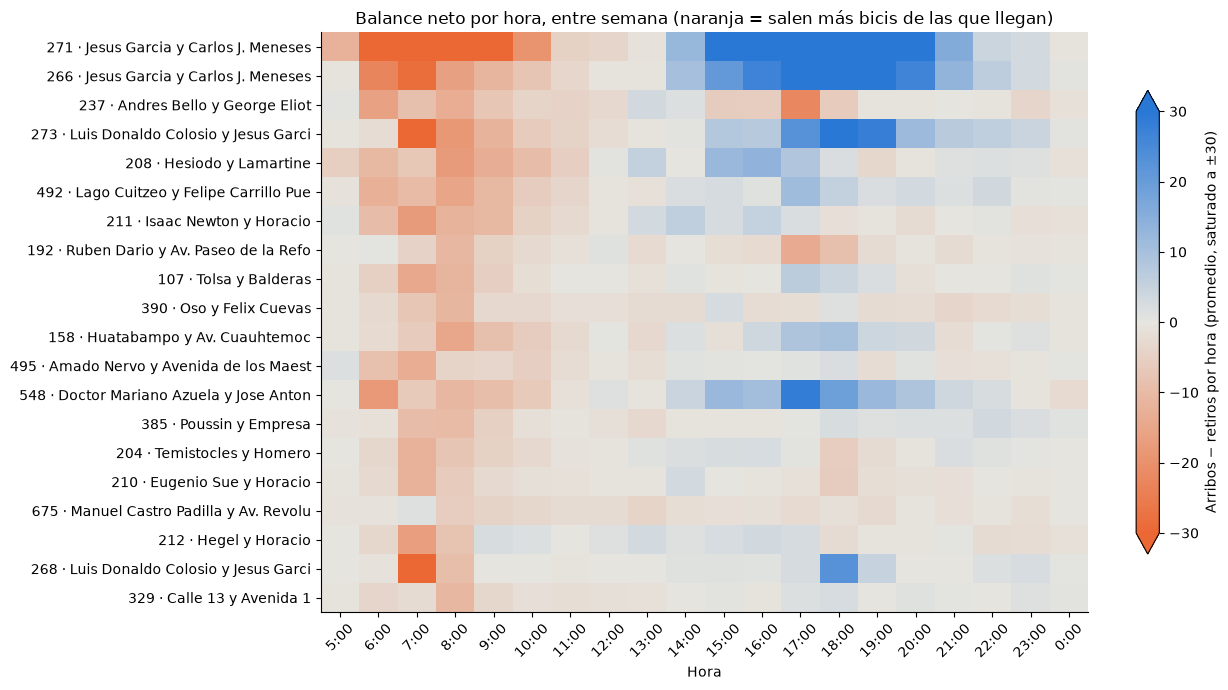

In [10]:
top20 = nec.nlargest(20, "Necesidad_mediana").index
calor = flujo[~es_finde].groupby(level="est").mean().loc[top20, range(20)]
lim = 30  # se satura a ±30 para que la 271 no apague al resto

fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(calor, cmap=DIVERGENTE, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
ax.set_yticks(range(len(top20)), nec.loc[top20, "Etiqueta"])
ax.set_xticks(range(20), horas_reloj, rotation=45)
ax.grid(False)
ax.set(title="Balance neto por hora, entre semana (naranja = salen más bicis de las que llegan)", xlabel="Hora")
fig.colorbar(im, ax=ax, label="Arribos − retiros por hora (promedio, saturado a ±30)", shrink=0.8, extend="both")
plt.tight_layout()
plt.show()

## 6. Entre semana vs. fin de semana

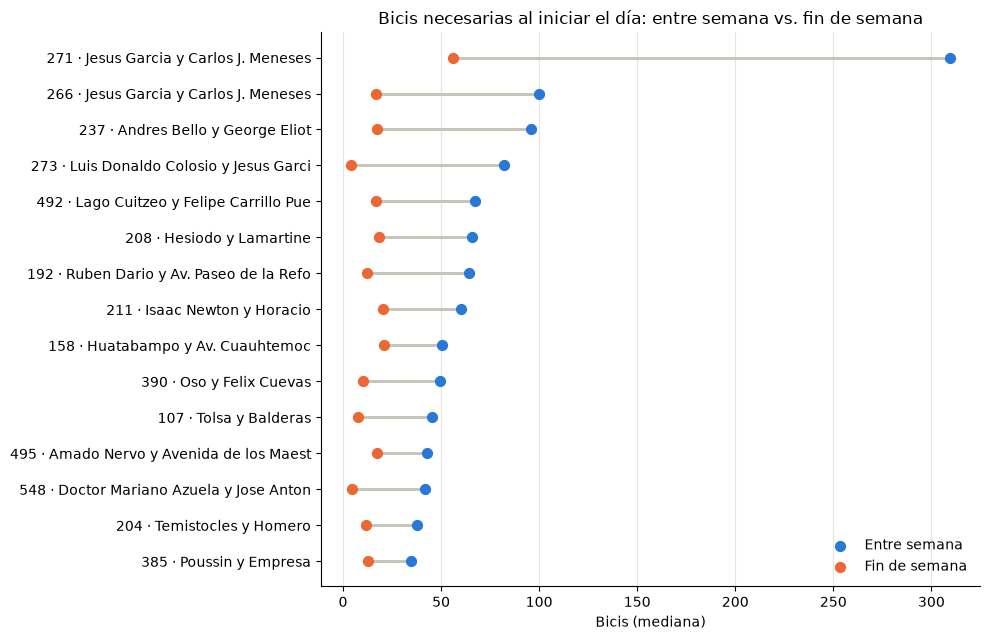

Necesidad total (suma de medianas):
  entre semana:  6,812 bicis
  fin de semana: 3,952 bicis


In [11]:
comp = nec.nlargest(15, "Necesidad_mediana").sort_values("Nec_entre_semana")

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.hlines(comp["Etiqueta"], comp["Nec_fin_semana"], comp["Nec_entre_semana"], color="#c3c2b7", linewidth=2)
ax.scatter(comp["Nec_entre_semana"], comp["Etiqueta"], color=PAL[0], s=50, zorder=3, label="Entre semana")
ax.scatter(comp["Nec_fin_semana"], comp["Etiqueta"], color=PAL[1], s=50, zorder=3, label="Fin de semana")
ax.set(title="Bicis necesarias al iniciar el día: entre semana vs. fin de semana", xlabel="Bicis (mediana)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

print("Necesidad total (suma de medianas):")
print(f"  entre semana:  {nec['Nec_entre_semana'].sum():,.0f} bicis")
print(f"  fin de semana: {nec['Nec_fin_semana'].sum():,.0f} bicis")

## 7. Estructural vs. pico: tipos de estación
Cruzando las dos métricas salen tres perfiles:
- **Vaciado crónico** (abajo-derecha): pierden bicis todo el día y todos los días → más bicis o rebalanceo diario.
- **Pico de commuters** (arriba-derecha): se vacían en la mañana pero se llenan en la tarde → stock alto al abrir, sin bicis extra permanentes.
- Las demás se mantienen cerca del equilibrio.

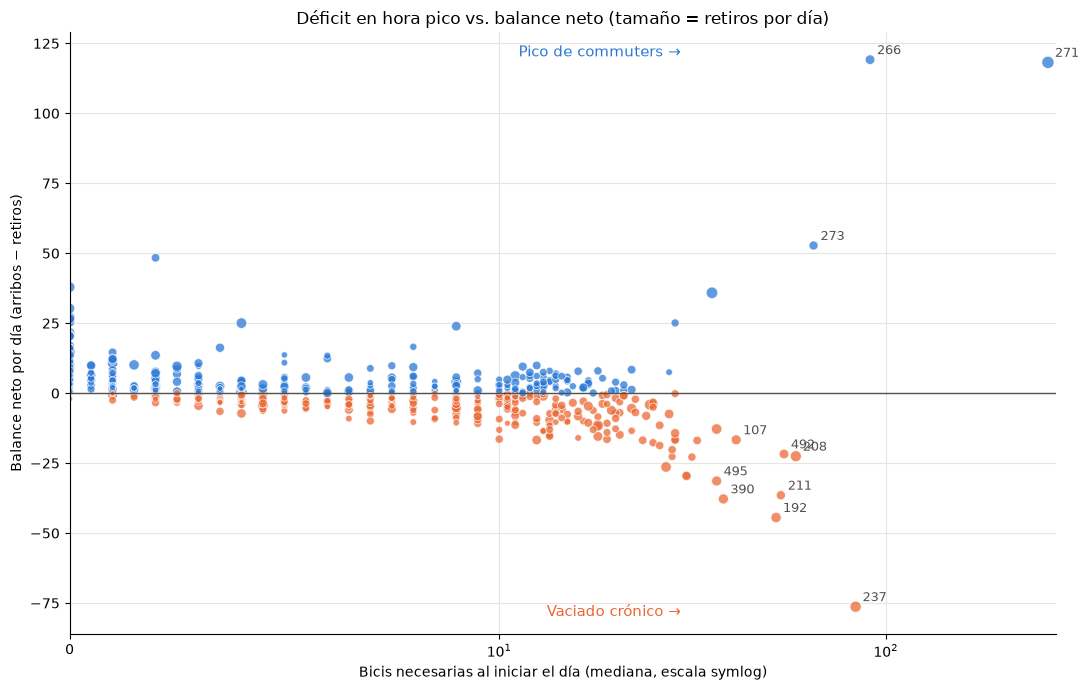

In [12]:
fig, ax = plt.subplots(figsize=(11, 7))
color_p = np.where(nec["Neto_dia"] < 0, NARANJA, AZUL)
ax.scatter(nec["Necesidad_mediana"], nec["Neto_dia"], c=color_p, s=np.sqrt(nec["Retiros_dia"]) * 4,
           alpha=0.75, edgecolors="white", linewidths=0.6)
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(left=0)
for est in nec.nlargest(10, "Necesidad_mediana").index.union(nec.nsmallest(5, "Neto_dia").index):
    f = nec.loc[est]
    ax.annotate(str(est), (f["Necesidad_mediana"], f["Neto_dia"]), xytext=(5, 4),
                textcoords="offset points", fontsize=9, color="#52514e")
ax.set(title="Déficit en hora pico vs. balance neto (tamaño = retiros por día)",
       xlabel="Bicis necesarias al iniciar el día (mediana, escala symlog)",
       ylabel="Balance neto por día (arribos − retiros)")
ax.text(0.62, 0.03, "Vaciado crónico →", transform=ax.transAxes, ha="right", color=NARANJA, fontsize=11)
ax.text(0.62, 0.96, "Pico de commuters →", transform=ax.transAxes, ha="right", color=AZUL, fontsize=11)
plt.tight_layout()
plt.show()

## 8. Dónde están: alcaldías y colonias

In [13]:
nec["Deficit_dia"] = (-nec["Neto_dia"]).clip(lower=0)

por_alcaldia = nec.groupby("Alcaldia").agg(
    Estaciones=("Estacion", "size"),
    Bicis_perdidas_dia=("Deficit_dia", "sum"),
    Necesidad_pico=("Necesidad_mediana", "sum"),
    Estaciones_criticas=("Necesidad_mediana", lambda s: (s >= 20).sum()),
).sort_values("Necesidad_pico", ascending=False)
por_alcaldia["Necesidad_por_estacion"] = por_alcaldia["Necesidad_pico"] / por_alcaldia["Estaciones"]
por_alcaldia.round(1)

,Estaciones,Bicis_perdidas_dia,Necesidad_pico,Estaciones_criticas,Necesidad_por_estacion
Alcaldia,,,,,
Cuauhtemoc,243,431.6,2432.0,29,10.0
Benito Juarez,213,550.8,1636.0,6,7.7
Miguel Hidalgo,139,887.7,1443.5,19,10.4
Azcapotzalco,28,6.0,237.0,0,8.5
Alvaro Obregon,17,89.3,112.0,1,6.6
Coyoacan,37,4.6,106.5,0,2.9


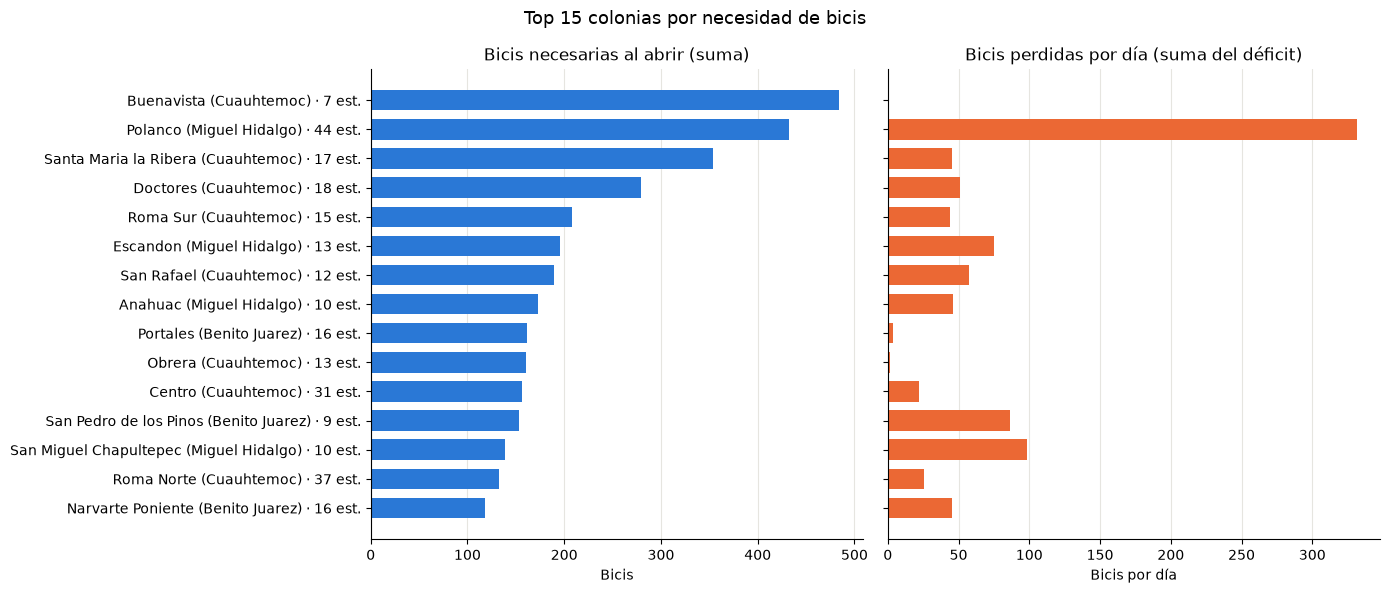

In [14]:
por_colonia = (nec.groupby(["Colonia", "Alcaldia"])
                  .agg(Estaciones=("Estacion", "size"),
                       Bicis_perdidas_dia=("Deficit_dia", "sum"),
                       Necesidad_pico=("Necesidad_mediana", "sum"))
                  .nlargest(15, "Necesidad_pico").sort_values("Necesidad_pico"))
etq = [f"{c} ({a}) · {n} est." for (c, a), n in zip(por_colonia.index, por_colonia["Estaciones"])]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
axes[0].barh(etq, por_colonia["Necesidad_pico"], color=PAL[0], height=0.7)
axes[0].set(title="Bicis necesarias al abrir (suma)", xlabel="Bicis")
axes[1].barh(etq, por_colonia["Bicis_perdidas_dia"], color=NARANJA, height=0.7)
axes[1].set(title="Bicis perdidas por día (suma del déficit)", xlabel="Bicis por día")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("Top 15 colonias por necesidad de bicis", fontsize=13)
plt.tight_layout()
plt.show()

## 9. Mapas
**Mapa 1:** color = balance neto diario (naranja: pierde bicis, azul: gana); tamaño = bicis necesarias al abrir.
Las 20 estaciones con más necesidad llevan borde negro. Pasa el mouse para ver el detalle.

In [15]:
def tooltip(est, f):
    hora = f"<br>Hora en que se vacía: {f.Hora_pico:.0f}:00" if pd.notna(f.Hora_pico) else ""
    return (f"<b>{f.Estacion}</b><br>Estación {est} · {f.Colonia}, {f.Alcaldia}"
            f"<br>Bicis necesarias al abrir: <b>{f.Necesidad_mediana:.0f}</b> (p90: {f.Necesidad_p90:.0f})"
            f"<br>Balance neto: {f.Neto_dia:+.1f} bicis/día · en déficit {f.Dias_deficit:.0f}/{n_dias} días" + hora)


def mapa_base(titulo):
    fig = folium.Figure(height=700)
    m = folium.Map(tiles="OpenStreetMap", zoom_snap=0.25).add_to(fig)
    m.fit_bounds([[estaciones["latitud"].min(), estaciones["longitud"].min()],
                  [estaciones["latitud"].max(), estaciones["longitud"].max()]])
    m.get_root().html.add_child(folium.Element(
        f'<div style="position:absolute; top:10px; left:55px; z-index:1000; background:white; padding:4px 10px;'
        f' border-radius:4px; box-shadow:0 1px 4px rgba(0,0,0,.3); font:14px sans-serif;"><b>{titulo}</b></div>'))
    return fig, m


datos_mapa = nec.join(estaciones[["latitud", "longitud"]]).sort_values("Necesidad_mediana")  # grandes encima
top20_set = set(nec.nlargest(20, "Necesidad_mediana").index)

LIM = 40  # bicis/día; más allá se satura el color
escala = LinearColormap([NARANJA, NEUTRO, AZUL], vmin=-LIM, vmax=LIM,
                        caption="Balance neto (arribos − retiros por día)")

fig1, m1 = mapa_base("Estaciones que más necesitan bicis · septiembre 2026")
for est, f in datos_mapa.iterrows():
    critica = est in top20_set
    folium.CircleMarker(
        [f.latitud, f.longitud],
        radius=2 + 1.1 * np.sqrt(f.Necesidad_mediana),
        color="#0b0b0b" if critica else "white", weight=2 if critica else 0.8,
        fill=True, fill_color=escala(np.clip(f.Neto_dia, -LIM, LIM)), fill_opacity=0.85,
        tooltip=tooltip(est, f),
    ).add_to(m1)
escala.add_to(m1)
fig1

**Mapa 2:** a qué hora se vacía cada estación con necesidad ≥ 10 bicis. Sirve para planear las rutas de rebalanceo
(qué zonas atender temprano y cuáles en la tarde).

In [16]:
FRANJAS = [("Mañana (5–11 h)", range(5, 12), NARANJA),
           ("Mediodía (12–16 h)", range(12, 17), PAL[3]),
           ("Tarde-noche (17–0 h)", [17, 18, 19, 20, 21, 22, 23, 0], PAL[6])]

fig2, m2 = mapa_base("¿A qué hora se vacían? · estaciones con necesidad ≥ 10 bicis")
otras = datos_mapa[datos_mapa["Necesidad_mediana"] < 10]
for est, f in otras.iterrows():
    folium.CircleMarker([f.latitud, f.longitud], radius=2.5, color=GRIS, weight=0.8, fill=False,
                        tooltip=f"Estación {est} · necesidad baja").add_to(m2)
for nombre, horas, color in FRANJAS:
    capa = folium.FeatureGroup(name=nombre).add_to(m2)
    sub = datos_mapa[(datos_mapa["Necesidad_mediana"] >= 10) & datos_mapa["Hora_pico"].isin(horas)]
    for est, f in sub.iterrows():
        folium.CircleMarker(
            [f.latitud, f.longitud], radius=2 + 1.1 * np.sqrt(f.Necesidad_mediana),
            color="white", weight=0.8, fill=True, fill_color=color, fill_opacity=0.85,
            tooltip=tooltip(est, f),
        ).add_to(capa)
leyenda = "".join(f'<div><span style="display:inline-block;width:12px;height:12px;border-radius:50%;'
                  f'background:{c};margin-right:6px"></span>{n}</div>' for n, _, c in FRANJAS)
m2.get_root().html.add_child(folium.Element(
    f'<div style="position:absolute; bottom:25px; right:10px; z-index:1000; background:white; padding:6px 10px;'
    f' border-radius:4px; box-shadow:0 1px 4px rgba(0,0,0,.3); font:12px sans-serif;">{leyenda}</div>'))
folium.LayerControl(collapsed=False).add_to(m2)
fig2

In [17]:
# Guardar los mapas como HTML para compartirlos fuera del notebook
from pathlib import Path
Path("mapas").mkdir(exist_ok=True)
fig1.save("mapas/necesidad_bicis.html")
fig2.save("mapas/hora_vaciado.html")

## 10. Ranking final
- **Stock sugerido al abrir** = percentil 90 de las bicis necesarias: cubre 9 de cada 10 días.
- **Tipo**: *Vaciado crónico* si cerró en déficit al menos 20 de los 30 días; si no, *Pico de commuters*.

In [18]:
ranking = nec.nlargest(25, "Necesidad_mediana").copy()
ranking["Tipo"] = np.where(ranking["Dias_deficit"] >= 20, "Vaciado crónico", "Pico de commuters")
ranking = ranking[["Estacion", "Colonia", "Alcaldia", "Tipo", "Necesidad_mediana", "Necesidad_p90",
                   "Neto_dia", "Dias_deficit", "Hora_pico", "Retiros_dia"]].rename(columns={
    "Necesidad_mediana": "Bicis al abrir (mediana)", "Necesidad_p90": "Stock sugerido (p90)",
    "Neto_dia": "Neto por día", "Dias_deficit": "Días en déficit", "Hora_pico": "Se vacía a las",
    "Retiros_dia": "Retiros por día"})
ranking.round(1)

,Estacion,Colonia,Alcaldia,Tipo,Bicis al abrir (mediana),Stock sugerido (p90),Neto por día,Días en déficit,Se vacía a las,Retiros por día
271,Jesus Garcia y Carlos J. Meneses,Buenavista,Cuauhtemoc,Pico de commuters,262.5,357.2,118.2,5,13.0,375.3
266,Jesus Garcia y Carlos J. Meneses,Buenavista,Cuauhtemoc,Pico de commuters,91.0,127.2,119.2,0,10.0,145.9
237,Andres Bello y George Eliot,Polanco,Miguel Hidalgo,Vaciado crónico,83.5,131.6,-76.3,29,23.0,258.9
273,Luis Donaldo Colosio y Jesus Garcia,Buenavista,Cuauhtemoc,Pico de commuters,65.0,124.7,52.8,1,12.0,113.1
208,Hesiodo y Lamartine,Polanco,Miguel Hidalgo,Vaciado crónico,58.5,93.3,-22.5,25,11.0,246.2
492,Lago Cuitzeo y Felipe Carrillo Puerto,Anahuac,Miguel Hidalgo,Vaciado crónico,54.5,89.3,-21.7,25,13.0,143.6
211,Isaac Newton y Horacio,Polanco,Miguel Hidalgo,Vaciado crónico,53.5,81.2,-36.5,28,11.0,121.3
192,Ruben Dario y Av. Paseo de la Reforma,Bosque de Chapultepec,Miguel Hidalgo,Vaciado crónico,52.0,81.0,-44.4,28,21.0,186.1
107,Tolsa y Balderas,Centro,Cuauhtemoc,Vaciado crónico,41.0,51.2,-16.7,23,16.0,161.1
390,Oso y Felix Cuevas,Actipan,Benito Juarez,Vaciado crónico,38.0,71.1,-37.8,30,0.0,173.1


## Conclusiones
1. **El desbalance es estructural y está concentrado.** 350 de 677 estaciones (52 %) pierden bicis en el mes; entre todas
   salen ~1,970 bicis por día que hay que reponer con rebalanceo. 81 estaciones cierran en déficit al menos 25 de 30 días.
2. **Polanco es el foco de vaciado crónico.** La 237 (Andrés Bello y George Eliot) pierde ~76 bicis diarias y cierra en
   negativo 29 de 30 días. Polanco suma ~330 bicis perdidas por día y aporta 6 de las 25 estaciones del ranking;
   Miguel Hidalgo es la alcaldía que más bicis pierde (~890/día) aunque tiene menos estaciones que Cuauhtémoc o Benito Juárez.
   **Aquí sí hacen falta más bicis de forma permanente** (o rebalanceo diario garantizado).
3. **Buenavista es un pico de commuters, no un déficit.** Las 271, 266, 273 y 268 se vacían de 6:00 a 13:00 (la 271 necesita
   ~260 bicis en un día típico y ~310 entre semana) y desde las 17:00 se llenan de más: terminan con +120 bicis/día.
   Necesitan un **stock muy alto al abrir** y retirar el excedente en la noche, no bicis nuevas.
4. **Las estaciones tocan fondo entre 8:00–9:00 y 12:00–13:00.** El rebalanceo debe llegar antes de las 7:00 y repetir a media mañana.
   Solo 34 de las 211 estaciones con más necesidad se vacían en la tarde-noche (17:00–0:00); la mitad están en Miguel Hidalgo
   (San Miguel Chapultepec, Polanco, Lomas).
5. **El fin de semana la presión baja ~42 %** (6,812 → 3,952 bicis necesarias sumando todas las estaciones), así que el
   refuerzo se puede concentrar de lunes a viernes.

**Limitaciones**: no hay datos de capacidad (anclajes), inventario ni rebalanceo; la necesidad se infiere solo de los viajes.
Valores como los 260 de la 271 superan cualquier estación física: significan que esa estación recibe rebalanceo continuo o una
operación especial. Siguiente paso: cruzar con la capacidad de cada estación (feed GBFS `station_information`) para
traducir la necesidad en anclajes y bicis faltantes.